(sec-3-2)=
# 3.2 Linearity and Superposition

Suppose we add baseline drift to an ECG and then filter the result. Would we get the same answer by filtering the ECG and the drift separately, then adding the two outputs? For a linear filter, we would. I find this question a useful starting point because it connects a mathematical property to a practical filtering experiment.

We will work through the two conditions for linearity, test a few simple systems by hand, and check them in Python. After that, we will use a real ECG to see why processing the components separately can help us understand a filter's behavior.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import wfdb
from scipy import signal
from matplotlib.patches import FancyBboxPatch, Circle

plt.style.use("../bsp.mplstyle")
C = plt.rcParams["axes.prop_cycle"].by_key()["color"]
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

(sec-3-2-1)=
## 3.2.1 Additivity, Homogeneity and Superposition

Let $\mathcal{T}$ be a system, and let $y_1 = \mathcal{T}\{x_1\}$ and $y_2 = \mathcal{T}\{x_2\}$ be its responses to two arbitrary inputs. Linearity is the combination of two separate requirements.

**Additivity.** The response to a sum is the sum of the responses:

$$
\mathcal{T}\{x_1 + x_2\} = \mathcal{T}\{x_1\} + \mathcal{T}\{x_2\} = y_1 + y_2 \quad\text{for all } x_1, x_2 .
$$

We can read this equality as two routes through the same experiment. On the left, we add the inputs first and process their sum. On the right, we process each input first and add the outputs. For the gain rule $\mathcal{T}\{x\}=2x$ and sample values $x_1=0.3$, $x_2=0.1$, both routes give $0.8$. Agreement in one example illustrates additivity; proving it requires agreement for every allowed pair of signals.

**Homogeneity (scaling).** Scaling the input by any constant $a$ scales the output by the same constant:

$$
\mathcal{T}\{a\,x\} = a\,\mathcal{T}\{x\} \quad\text{for all } x \text{ and all scalars } a.
$$

A system that satisfies both is **linear**. The two conditions can be merged into a single statement, the **superposition principle**:

(eq-3-14)=
\begin{equation*}
\mathcal{T}\{a_1 x_1 + a_2 x_2\} = a_1\,\mathcal{T}\{x_1\} + a_2\,\mathcal{T}\{x_2\}. \tag{3.14}
\end{equation*}

To see that [(3.14)](#eq-3-14) is equivalent to the pair of conditions, first apply additivity to split the sum, then homogeneity to pull out each constant: $\mathcal{T}\{a_1 x_1 + a_2 x_2\} = \mathcal{T}\{a_1 x_1\} + \mathcal{T}\{a_2 x_2\} = a_1\mathcal{T}\{x_1\} + a_2\mathcal{T}\{x_2\}$. Conversely, choosing $a_1 = a_2 = 1$ in [(3.14)](#eq-3-14) gives additivity, and choosing $a_2 = 0$ gives homogeneity. Applying [(3.14)](#eq-3-14) repeatedly, one term at a time, extends it to any finite number of inputs:

(eq-3-15)=
\begin{equation*}
\mathcal{T}\left\{\sum_{k=1}^{K} a_k\,x_k\right\} = \sum_{k=1}^{K} a_k\,\mathcal{T}\{x_k\}. \tag{3.15}
\end{equation*}

This is the form we will use most. It says that if a signal can be written as a weighted sum of simple pieces, the response is the same weighted sum of the responses to the pieces. (Extending [(3.15)](#eq-3-15) to infinite sums and integrals, as Chapters 4 and 8 do, requires a mild continuity assumption that every system in this book satisfies.)

### Zero in, zero out

A useful consequence follows from homogeneity with $a = 0$. For any input $x$,

$$
\mathcal{T}\{0\} = \mathcal{T}\{0\cdot x\} = 0\cdot\mathcal{T}\{x\} = 0 .
$$

A linear system must answer a zero input with a zero output. This gives a quick screening test: if a system produces a nonzero output when nothing goes in, it cannot be linear. The converse is false, as the squarer will show: $0^2 = 0$, yet squaring is far from linear.

### The two conditions are independent

It is tempting to check only one of the two conditions, but neither implies the other. Complex conjugation, $\mathcal{T}\{x\} = x^*$, is additive, since $(x_1 + x_2)^* = x_1^* + x_2^*$, but it is not homogeneous for complex constants: $\mathcal{T}\{j\,x\} = (j\,x)^* = -j\,x^*$, whereas $j\,\mathcal{T}\{x\} = j\,x^*$. In the other direction, the median filter of Example 3.2.6 below is homogeneous but not additive. A linearity proof must therefore establish both, or establish [(3.14)](#eq-3-14) directly.

### A recipe for testing linearity by hand

All of the examples below follow the same three steps, and I recommend writing them out explicitly every time.

1. Take two arbitrary inputs $x_1$, $x_2$ with outputs $y_1$, $y_2$ computed from the system's definition.
2. Form the combined input $x_3 = a\,x_1 + b\,x_2$ and compute its output $y_3 = \mathcal{T}\{x_3\}$, again from the definition.
3. Compare $y_3$ with $a\,y_1 + b\,y_2$. If they are equal for *every* choice of inputs and constants, the system is linear. A *single* counterexample proves that it is not.

(sec-3-2-2)=
## 3.2.2 Worked Examples

**Example 3.2.1.** Is the squarer $y(t) = x^2(t)$ linear?

The squarer appears in every energy detector and in the QRS detector of Section 3.1. We follow the recipe.

*Step 1.* The individual outputs are $y_1(t) = x_1^2(t)$ and $y_2(t) = x_2^2(t)$.

*Step 2.* For $x_3(t) = a\,x_1(t) + b\,x_2(t)$, expanding the square,

$$
\begin{aligned}
y_3(t) = x_3^2(t) &= \big(a\,x_1(t) + b\,x_2(t)\big)^2 \\[2pt]
&= a^2 x_1^2(t) + 2ab\,x_1(t)\,x_2(t) + b^2 x_2^2(t).
\end{aligned}
$$

*Step 3.* The superposition of the individual outputs is $a\,y_1(t) + b\,y_2(t) = a\,x_1^2(t) + b\,x_2^2(t)$. Comparing term by term, two things go wrong: the constants appear squared ($a^2$ instead of $a$), so homogeneity fails, and there is a **cross term** $2ab\,x_1 x_2$, so additivity fails. A concrete counterexample settles it: for the constant input $x(t) = 1$ and $a = 2$, $\mathcal{T}\{2\} = 4$ while $2\,\mathcal{T}\{1\} = 2$. The squarer is **not linear**, even though it passes the zero-in, zero-out test.

**Example 3.2.2.** Is $y(t) = t\,x(t)$ linear?

This system multiplies the input by a ramp. It looks unusual, but it is the prototype of a system whose gain changes with time.

*Step 1.* $y_1(t) = t\,x_1(t)$ and $y_2(t) = t\,x_2(t)$.

*Step 2.* For $x_3(t) = a\,x_1(t) + b\,x_2(t)$, distributing the factor $t$,

$$
y_3(t) = t\,x_3(t) = t\,\big(a\,x_1(t) + b\,x_2(t)\big) = a\,t\,x_1(t) + b\,t\,x_2(t).
$$

*Step 3.* The right-hand side is exactly $a\,y_1(t) + b\,y_2(t)$, for every choice of inputs and constants. The system is **linear**. The factor $t$ makes the gain depend on time, but linearity only asks how the output depends on the *input*, and that dependence is a plain multiplication. Whether a time-dependent gain matters for other properties is the subject of Section 4.3, where this same system turns out to be time-varying.

**Example 3.2.3.** Is $y[n] = 2\,x[n] + 3$ linear?

At first sight this is the equation of a straight line, and many students answer "yes". The recipe says otherwise.

*Step 1.* $y_1[n] = 2x_1[n] + 3$ and $y_2[n] = 2x_2[n] + 3$.

*Step 2.* For $x_3[n] = a\,x_1[n] + b\,x_2[n]$,

$$
y_3[n] = 2\,\big(a\,x_1[n] + b\,x_2[n]\big) + 3 = 2a\,x_1[n] + 2b\,x_2[n] + 3 .
$$

*Step 3.* The superposition of the individual outputs is

$$
a\,y_1[n] + b\,y_2[n] = 2a\,x_1[n] + 2b\,x_2[n] + 3(a + b).
$$

The two expressions agree only when $a + b = 1$, so the system is **not linear**. The zero-in, zero-out test finds the problem even faster: $x[n] = 0$ gives $y[n] = 3$.

Yet the system is clearly "almost" linear, and it helps to say exactly in what sense. Take the *difference* of the responses to two inputs:

$$
y_1[n] - y_2[n] = \big(2x_1[n] + 3\big) - \big(2x_2[n] + 3\big) = 2\,\big(x_1[n] - x_2[n]\big).
$$

Changes in the output are a linear function of changes in the input. Systems with this property are called **incrementally linear** (or *affine*). Every such system can be written as a linear system plus a fixed **zero-input response** $y_0$, the output when the input is zero:

$$
y[n] = \underbrace{2\,x[n]}_{\text{linear part}} \;+\; \underbrace{3}_{y_0[n]} .
$$

The block diagram below makes the structure visible. Incrementally linear systems are everywhere in instrumentation: the electrode with its half-cell potential from {ref}`Section 3.1.2 <sec-3-1-2>`, an amplifier with an input offset voltage, a pressure transducer that reads 2 mmHg when open to air. In practice we estimate and subtract the offset (or remove it with a high-pass filter) and treat what remains as linear. The same decomposition into a zero-input and a zero-state response reappears for difference equations with nonzero initial conditions in [Section 5.5](../ch05_convolution/index.md).

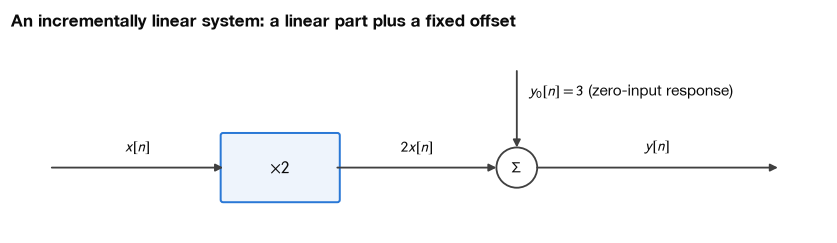

In [2]:
def block(ax, x, y, text, w=1.4, h=0.8):
    """Draw a system block centered at (x, y)."""
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.03",
                                fc="#eef4fc", ec=C[0], lw=1.3))
    ax.text(x, y, text, ha="center", va="center", fontsize=11)


def arrow(ax, start, end, label=None, dy=0.15):
    """Draw a signal arrow with an optional label above its midpoint."""
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color="0.25", lw=1.2, shrinkA=0, shrinkB=0))
    if label:
        ax.text((start[0] + end[0]) / 2, (start[1] + end[1]) / 2 + dy, label, ha="center",
                va="bottom", fontsize=10)


fig, ax = plt.subplots(figsize=(7.5, 2.1))
ax.set(xlim=(0, 10), ylim=(0, 2.4))
ax.axis("off")
arrow(ax, (0.5, 0.8), (2.6, 0.8), "$x[n]$")
block(ax, 3.3, 0.8, r"$\times 2$")
arrow(ax, (4.0, 0.8), (5.95, 0.8), r"$2x[n]$")
ax.add_patch(Circle((6.2, 0.8), 0.25, fc="white", ec="0.25", lw=1.2))
ax.text(6.2, 0.8, r"$\Sigma$", ha="center", va="center", fontsize=10)
arrow(ax, (6.2, 2.0), (6.2, 1.05))
ax.text(6.35, 1.75, r"$y_0[n] = 3$ (zero-input response)", ha="left", va="center", fontsize=10)
arrow(ax, (6.45, 0.8), (9.4, 0.8), "$y[n]$")
ax.set_title(r"An incrementally linear system: a linear part plus a fixed offset")
plt.show()

**Example 3.2.4.** Is the modulator $y(t) = x(t)\cos(\omega_0 t)$ linear?

Multiplying a signal by a sinusoidal carrier is the basis of amplitude modulation, and it is how many bedside monitors measure breathing through the ECG electrodes: a small high-frequency current is injected across the chest, the changing thoracic impedance modulates its amplitude, and the receiver multiplies by the carrier again to recover the respiration signal.

*Step 1.* $y_1(t) = x_1(t)\cos(\omega_0 t)$ and $y_2(t) = x_2(t)\cos(\omega_0 t)$.

*Step 2.* For $x_3(t) = a\,x_1(t) + b\,x_2(t)$,

$$
y_3(t) = \big(a\,x_1(t) + b\,x_2(t)\big)\cos(\omega_0 t) = a\,x_1(t)\cos(\omega_0 t) + b\,x_2(t)\cos(\omega_0 t).
$$

*Step 3.* This equals $a\,y_1(t) + b\,y_2(t)$, so the modulator is **linear**. It has exactly the structure of Example 3.2.2, with the ramp $t$ replaced by the carrier $\cos(\omega_0 t)$: any system of the form $y(t) = g(t)\,x(t)$ is linear, whatever the function $g$.

**Example 3.2.5.** Is the full-wave rectifier $y = |x|$ linear?

Homogeneity with $a = -1$ fails immediately: $\mathcal{T}\{-x\} = |-x| = |x|$, while $-\mathcal{T}\{x\} = -|x|$, and these differ whenever $x \neq 0$. Additivity fails too. With the constant inputs $x_1 = 1$ and $x_2 = -1$, the response to the sum is $|1 + (-1)| = 0$, but the sum of the responses is $|1| + |-1| = 2$. The rectifier is **not linear**. It does satisfy homogeneity for *non-negative* constants, $|a\,x| = a\,|x|$ for $a \ge 0$, which is why a rectifier followed by a smoother still gives an envelope proportional to the signal's amplitude, the property that makes it useful for EMG.

**Example 3.2.6.** Is the three-point median filter linear?

The median filter replaces each sample by the middle value of a sorted window,

$$
y[n] = \operatorname{median}\{x[n-1],\, x[n],\, x[n+1]\}.
$$

It is popular in ECG processing because it removes isolated spikes without blurring edges, and a cascade of two long median filters (200 ms and 600 ms) is a classic way to estimate baseline wander {cite:p}`dechazal2004`.

*Homogeneity holds.* Multiplying the window by $a > 0$ does not change the order of its values, so the middle value is multiplied by $a$. Multiplying by $a < 0$ reverses the order, but the middle element stays in the middle, so again $\operatorname{median}\{a\,w\} = a\,\operatorname{median}\{w\}$. The case $a = 0$ is trivial.

*Additivity fails.* We look at the output at $n = 0$ for two unit impulses placed on either side of it, $x_1[n] = \delta[n - 1]$ and $x_2[n] = \delta[n + 1]$. The windows around $n = 0$ are

$$
\begin{aligned}
x_1:\ \{0, 0, 1\} &\;\Rightarrow\; y_1[0] = 0, \\
x_2:\ \{1, 0, 0\} &\;\Rightarrow\; y_2[0] = 0, \\
x_1 + x_2:\ \{1, 0, 1\} &\;\Rightarrow\; \mathcal{T}\{x_1 + x_2\}[0] = 1 \neq y_1[0] + y_2[0] = 0 .
\end{aligned}
$$

Each impulse on its own is treated as an outlier and removed, but together they form the majority of the window. The median filter is homogeneous but **not linear**. This is not a defect; it is precisely the nonlinearity that lets a median filter remove a spike that a linear smoother would only spread out.

The next cell checks the hand calculations of Examples 4.2.1, 4.2.3, 4.2.5 and 4.2.6 with the specific counterexamples used above.

In [3]:
def median3(x):
    """Three-point median filter with zero padding at both ends."""
    windows = np.lib.stride_tricks.sliding_window_view(np.pad(x, 1), 3)
    return np.median(windows, axis=1)


one = np.array([1.0])
print(f"Squarer:    T{{2}} = {(2 * one)[0] ** 2:.0f},  2 T{{1}} = {2 * one[0] ** 2:.0f}")
print(f"2x + 3:     T{{0}} = {2 * 0 + 3},  T{{1+1}} = {2 * 2 + 3},  T{{1}} + T{{1}} = {2 * (2 * 1 + 3)}")
print(f"Rectifier:  T{{1 + (-1)}} = {abs(1 - 1)},  T{{1}} + T{{-1}} = {abs(1) + abs(-1)}")

x1 = np.array([0.0, 0.0, 0.0, 1.0, 0.0])    # n = -2..2, impulse at n = +1
x2 = np.array([0.0, 1.0, 0.0, 0.0, 0.0])    # impulse at n = -1
print(f"Median:     T{{x1}}[0] = {median3(x1)[2]:.0f},  T{{x2}}[0] = {median3(x2)[2]:.0f},  "
      f"T{{x1 + x2}}[0] = {median3(x1 + x2)[2]:.0f}")
w = rng.standard_normal(9)
print(f"Median homogeneity with a = -2.5: max |T{{a w}} - a T{{w}}| = {np.max(np.abs(median3(-2.5 * w) + 2.5 * median3(w))):.1e}")

Squarer:    T{2} = 4,  2 T{1} = 2
2x + 3:     T{0} = 3,  T{1+1} = 7,  T{1} + T{1} = 10
Rectifier:  T{1 + (-1)} = 0,  T{1} + T{-1} = 2
Median:     T{x1}[0] = 0,  T{x2}[0] = 0,  T{x1 + x2}[0] = 1
Median homogeneity with a = -2.5: max |T{a w} - a T{w}| = 0.0e+00


(sec-3-2-3)=
## 3.2.3 A Numerical Linearity Tester

Hand derivations are the only way to *prove* linearity, but a numerical test is a quick and reliable way to *disprove* it, and it is invaluable for checking code: an implementation bug often shows up as a broken superposition. The idea is to feed the system random inputs and random constants and measure how badly equation [(3.14)](#eq-3-14) fails. Additivity and homogeneity are measured separately, so that we can see which of the two is violated. We compare outputs with the relative error

$$
\varepsilon = \frac{\lVert \mathbf{u} - \mathbf{v} \rVert}{\max\big(\lVert \mathbf{u}\rVert, \lVert \mathbf{v}\rVert\big)},
$$

where $\lVert\cdot\rVert$ is the Euclidean norm of [Section 2.2](../ch02_math_toolkit/index.md). For a linear system implemented in floating point, $\varepsilon$ is of the order of $10^{-16}$; anything above about $10^{-9}$ signals a genuine violation.

In [4]:
def rel_err(u, v):
    """Relative difference between two output signals."""
    return np.linalg.norm(u - v) / max(np.linalg.norm(u), np.linalg.norm(v), 1e-300)


def test_linearity(system, n_samples=400, n_trials=20, scale=1.0, rng=rng):
    """Worst additivity and homogeneity errors of `system` over random inputs and constants."""
    add_err = hom_err = 0.0
    for _ in range(n_trials):
        x1, x2 = scale * rng.standard_normal((2, n_samples))
        a = 3 * rng.standard_normal()
        add_err = max(add_err, rel_err(system(x1 + x2), system(x1) + system(x2)))
        hom_err = max(hom_err, rel_err(system(a * x1), a * system(x1)))
    return add_err, hom_err


Omega0 = 2 * np.pi * 0.05                         # carrier, rad/sample
systems = {
    "y = x^2": lambda x: x**2,
    "y[n] = n x[n]": lambda x: np.arange(x.size) * x,
    "y = 2x + 3": lambda x: 2 * x + 3,
    "y[n] = x[n] cos(Omega0 n)": lambda x: x * np.cos(Omega0 * np.arange(x.size)),
    "y = |x|": np.abs,
    "3-point median": median3,
    "5-point moving average": lambda x: np.convolve(x, np.ones(5) / 5)[: x.size],
    "first difference": lambda x: np.diff(x, prepend=0.0),
    "clip at +/-1": lambda x: np.clip(x, -1, 1),
}

rows = []
for name, system in systems.items():
    e_add, e_hom = test_linearity(system)
    rows.append({"system": name, "additivity error": e_add, "homogeneity error": e_hom,
                 "verdict": "linear" if max(e_add, e_hom) < 1e-9 else "NOT linear"})
table = pd.DataFrame(rows).set_index("system")
print(table.to_string(float_format=lambda v: f"{v:.1e}"))

                           additivity error  homogeneity error     verdict
system                                                                    
y = x^2                             6.6e-01            1.9e+00  NOT linear
y[n] = n x[n]                       1.1e-16            1.0e-16      linear
y = 2x + 3                          4.7e-01            1.6e+00  NOT linear
y[n] = x[n] cos(Omega0 n)           9.7e-17            1.0e-16      linear
y = |x|                             5.2e-01            2.0e+00  NOT linear
3-point median                      6.3e-01            0.0e+00  NOT linear
5-point moving average              1.5e-16            1.5e-16      linear
first difference                    1.0e-16            1.1e-16      linear
clip at +/-1                        4.4e-01            7.5e-01  NOT linear


The table agrees with every hand derivation. It also shows the *pattern* of failure: the median filter fails additivity but passes homogeneity, exactly as we proved, while the squarer, the rectifier and the affine system $2x + 3$ fail both.

The last row deserves a second look, because it holds a trap. A clipping amplifier is linear for any input that never reaches the rails. If we test it only with small inputs, it passes.

In [5]:
for scale in (0.1, 1.0):
    e_add, e_hom = test_linearity(systems["clip at +/-1"], scale=scale)
    print(f"clip at +/-1, input SD {scale:>3}: additivity error {e_add:.1e}, homogeneity error {e_hom:.1e}")

clip at +/-1, input SD 0.1: additivity error 0.0e+00, homogeneity error 1.4e-01
clip at +/-1, input SD 1.0: additivity error 4.3e-01, homogeneity error 8.1e-01


With inputs whose standard deviation is 0.1, the random test signals almost never approach $\pm 1$ (the largest combined input with $|a| < 3$ stays well inside), and the clipper looks perfectly linear. A numerical test is only as good as the inputs it uses. This mirrors a real engineering fact: most physical systems are linear only over a **linear range**, and an amplifier tested with a resting ECG may still fail when the patient moves.

```{important}
A numerical test can prove that a system is *not* linear, but it can never prove that it is. Passing the test means only that no violation was found for the inputs tried. Always test with inputs as large and as varied as the system will meet in practice.
```

(sec-3-2-4)=
## 3.2.4 Why Linearity Matters

Superposition turns one hard problem into many easy ones. If an input can be decomposed into simple pieces, $x = \sum_k a_k x_k$, then equation [(3.15)](#eq-3-15) says we only need the responses to the pieces. Two decompositions organize much of this book.

**Impulses.** Any discrete-time signal is a weighted sum of shifted unit impulses, $x[n] = \sum_k x[k]\,\delta[n - k]$. For a linear system, the output is therefore $\sum_k x[k]\,\mathcal{T}\{\delta[n - k]\}$, and if the system is also time-invariant, all of these responses are shifted copies of a single impulse response. That observation leads straight to convolution in [Chapter 4](../ch05_convolution/index.md).

**Sinusoids.** Many signals, the ECG among them, are well described as sums of sinusoids (Chapter 5). For a linear time-invariant system, each sinusoid comes out as a sinusoid at the same frequency with a new amplitude and phase, so the whole behavior of the system is captured by one complex number per frequency, the frequency response of Section 8.4.

### Why six points remove 60 Hz

We can now settle the question left open in {ref}`Section 3.1.1 <sec-3-1-1>`, where a six-point moving average removed a 60 Hz hum from an ECG sampled at 360 Hz. The moving average is linear, so its response to $\text{ECG} + \text{hum}$ is its response to the ECG plus its response to the hum, and we can study the hum alone. At $f_s = 360$ Hz, one period of a 60 Hz sinusoid lasts exactly $360/60 = 6$ samples. The six-point average of $\sin(2\pi\cdot 60\,n/360 + \varphi) = \sin(\pi n/3 + \varphi)$ is therefore an average over one complete period, which is zero for every $n$: the six samples are the imaginary parts of six unit phasors spaced by $60^\circ$, and those phasors sum to zero (the roots of unity of [Section 2.1](../ch02_math_toolkit/01_complex_numbers.ipynb)). The hum is annihilated, and the ECG passes with whatever distortion the average causes to it alone.

In [6]:
fs_demo = 360
n = np.arange(2000)
hum = 0.15 * np.sin(2 * np.pi * 60 * n / fs_demo + 0.7)
ma6 = np.convolve(hum, np.ones(6) / 6)[: n.size]
print(f"Largest |MA6{{hum}}| after the first 5 samples: {np.max(np.abs(ma6[5:])):.1e} mV")

Largest |MA6{hum}| after the first 5 samples: 2.3e-14 mV


(sec-3-2-5)=
## 3.2.5 Superposition on a Real ECG, Step by Step

The real payoff of superposition is that we can evaluate a processing system one noise component at a time. We now do this with a clean ECG from MIT-BIH record 100 {cite:p}`moody2001` and two real noise recordings from the MIT-BIH Noise Stress Test Database {cite:p}`moody1984,goldberger2000`: baseline wander (`bw`), recorded from electrodes placed where the ECG is negligible on an active subject, and muscle artifact (`ma`).

### Step 1: Build a noisy ECG from real components

We take 12 s of each recording, scale the muscle noise by 0.5 so that it is visible but does not hide the ECG, and add the three signals. Because the noise recordings are real, the sum looks and behaves like a difficult ambulatory ECG.

In [7]:
fs = 360
start, dur = 60 * fs, 12 * fs
ecg = wfdb.rdrecord("../data/mitdb/100", sampfrom=start, sampto=start + dur).p_signal[:, 0]
bw = wfdb.rdrecord("../data/nstdb/bw", sampfrom=start, sampto=start + dur).p_signal[:, 0]
ma = 0.5 * wfdb.rdrecord("../data/nstdb/ma", sampfrom=start, sampto=start + dur).p_signal[:, 0]
t = np.arange(dur) / fs

components = {"ECG (mitdb 100)": ecg, "Baseline wander (nstdb bw)": bw, "Muscle noise (nstdb ma, x0.5)": ma}
noisy = ecg + bw + ma
for name, comp in components.items():
    print(f"{name:<30s} RMS = {np.sqrt(np.mean(comp**2)):.3f} mV")
print(f"{'Noisy sum':<30s} RMS = {np.sqrt(np.mean(noisy**2)):.3f} mV")

ECG (mitdb 100)                RMS = 0.338 mV
Baseline wander (nstdb bw)     RMS = 0.341 mV
Muscle noise (nstdb ma, x0.5)  RMS = 0.088 mV
Noisy sum                      RMS = 0.463 mV


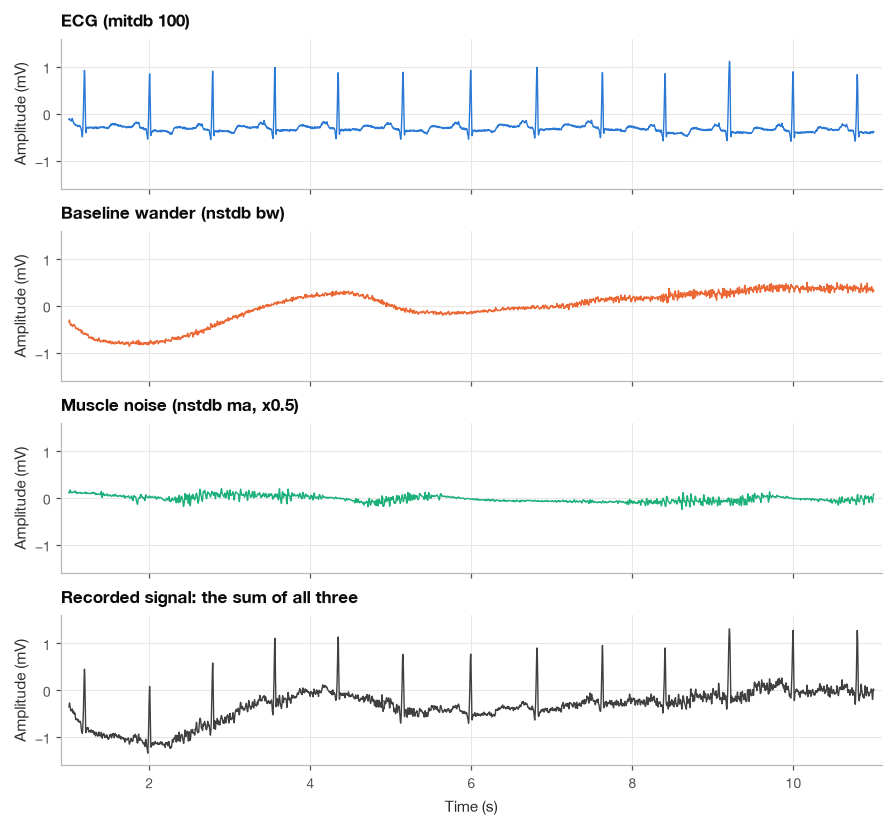

In [8]:
view = (t >= 1) & (t < 11)
fig, axes = plt.subplots(4, 1, figsize=(8, 7.4), sharex=True)
for ax, (name, comp), c in zip(axes, components.items(), C):
    ax.plot(t[view], comp[view], color=c, lw=0.9)
    ax.set(ylabel="Amplitude (mV)", title=name)
axes[3].plot(t[view], noisy[view], color="0.25", lw=0.9)
axes[3].set(xlabel="Time (s)", ylabel="Amplitude (mV)", title="Recorded signal: the sum of all three")
for ax in axes:
    ax.set_ylim(-1.6, 1.6)
plt.show()

### Step 2: Choose a linear system and apply it to the sum

As the processing system we use a simple baseline remover: subtract from each sample the average of the 0.6 s window centered on it,

$$
y[n] = x[n] - \frac{1}{217}\sum_{k=-108}^{108} x[n - k].
$$

The window is long enough to contain at least one full heartbeat, so the average follows the slow baseline but not the QRS complexes. The system is a parallel connection ({ref}`Section 3.1.5 <sec-3-1-5>`) of the identity and a negated moving average, and both branches are linear, so it is linear too. We discard the first and last second of each output, where the window runs off the ends of the record.

In [9]:
def baseline_remover(x, M=217):
    """Subtract a centered M-point moving average from x (a simple linear high-pass system)."""
    return x - np.convolve(x, np.ones(M) / M, mode="same")


y_sum = baseline_remover(noisy)
y_parts = {name: baseline_remover(comp) for name, comp in components.items()}
y_superposed = sum(y_parts.values())
print(f"Linear system: max |T{{sum}} - sum of T{{parts}}| = {np.max(np.abs(y_sum - y_superposed)):.1e} mV")

Linear system: max |T{sum} - sum of T{parts}| = 5.7e-16 mV


The response to the sum equals the sum of the responses to within rounding error, as equation [(3.15)](#eq-3-15) promises.

### Step 3: Evaluate the system one component at a time

Because superposition holds, the effect of the baseline remover on each component can be judged in isolation. That is how one evaluates a filter in practice: how much wander remains, how much the ECG itself is distorted, and how much muscle noise passes.

In [10]:
inner = view
rows = []
for name, comp in components.items():
    before = np.sqrt(np.mean(comp[inner] ** 2))
    after = np.sqrt(np.mean(y_parts[name][inner] ** 2))
    rows.append({"component": name, "RMS in (mV)": before, "RMS out (mV)": after, "out/in": after / before})
ecg_distortion = np.sqrt(np.mean((y_parts["ECG (mitdb 100)"] - (ecg - ecg.mean()))[inner] ** 2))
print(pd.DataFrame(rows).set_index("component").round(3).to_string())
print(f"RMS change of the zero-mean ECG caused by the system: {ecg_distortion:.3f} mV")

                               RMS in (mV)  RMS out (mV)  out/in
component                                                       
ECG (mitdb 100)                      0.342         0.171   0.500
Baseline wander (nstdb bw)           0.361         0.033   0.091
Muscle noise (nstdb ma, x0.5)        0.069         0.039   0.566
RMS change of the zero-mean ECG caused by the system: 0.032 mV


The baseline remover cuts the wander's RMS value by about three quarters while leaving the muscle noise essentially untouched, which is what we expect from a system that only subtracts a slow average: muscle noise is fast. The ECG itself is altered by a few hundredths of a millivolt once its mean is removed, mostly near the QRS complexes, whose energy leaks into the 0.6 s average. Every one of these statements was obtained from a separate, clean experiment, and superposition guarantees that together they describe what happens to the real, noisy recording.

### Step 4: Repeat with a nonlinear system

Now replace the baseline remover by the squarer. Superposition fails, and the difference between the response to the sum and the sum of the responses is made entirely of cross terms of the kind found in Example 3.2.1: $2\,\text{ECG}\cdot\text{bw} + 2\,\text{ECG}\cdot\text{ma} + 2\,\text{bw}\cdot\text{ma}$.

In [11]:
sq_sum = noisy**2
sq_superposed = sum(comp**2 for comp in components.values())
cross = 2 * (ecg * bw + ecg * ma + bw * ma)
print(f"Squarer: max |T{{sum}} - sum of T{{parts}}| = {np.max(np.abs(sq_sum - sq_superposed)):.3f} mV²")
print(f"Cross terms account for it exactly: max |difference - cross| = {np.max(np.abs(sq_sum - sq_superposed - cross)):.1e} mV²")

Squarer: max |T{sum} - sum of T{parts}| = 1.382 mV²
Cross terms account for it exactly: max |difference - cross| = 6.7e-16 mV²


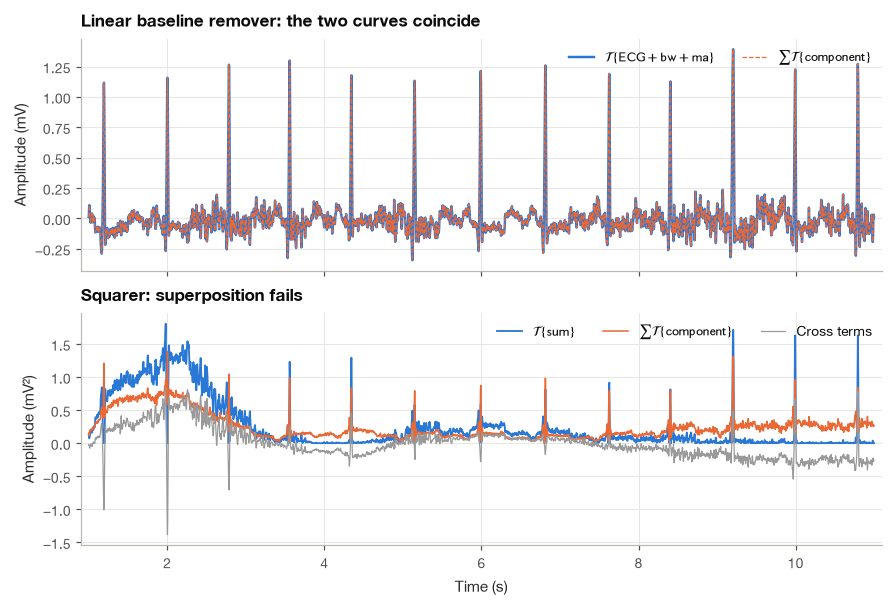

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(8, 5.4), sharex=True)
axes[0].plot(t[view], y_sum[view], color=C[0], lw=1.6, label=r"$\mathcal{T}\{\text{ECG} + \text{bw} + \text{ma}\}$")
axes[0].plot(t[view], y_superposed[view], color=C[1], lw=0.8, ls="--", label=r"$\sum \mathcal{T}\{\text{component}\}$")
axes[0].set(ylabel="Amplitude (mV)", title="Linear baseline remover: the two curves coincide")
axes[0].legend(loc="upper right", ncols=2)

axes[1].plot(t[view], sq_sum[view], color=C[0], lw=1.2, label=r"$\mathcal{T}\{\text{sum}\}$")
axes[1].plot(t[view], sq_superposed[view], color=C[1], lw=1.0, label=r"$\sum \mathcal{T}\{\text{component}\}$")
axes[1].plot(t[view], cross[view], color="0.6", lw=0.8, label="Cross terms")
axes[1].set(xlabel="Time (s)", ylabel="Amplitude (mV²)", title="Squarer: superposition fails")
axes[1].legend(loc="upper right", ncols=3)
plt.show()

With the squarer, nothing can be learned about the noisy recording from separate experiments. The output depends on how the ECG and the noise *interact*: the same R wave produces a large or a small squared peak depending on where the baseline happens to be, and the cross terms (gray) are as large as the squared signals themselves. This is the precise version of the observation we made on the squarer's output in Section 3.1.6.

(sec-3-2-6)=
## 3.2.6 Nonlinear Distortion Creates New Frequencies

A second consequence of nonlinearity is less obvious but just as important in practice: a nonlinear system can produce frequencies that were not present in its input. We start with a single sinusoid, $x(t) = A\cos(\omega_0 t)$.

**Squaring.** Using the identity $\cos^2\theta = \tfrac{1}{2}(1 + \cos 2\theta)$, which follows from adding $\cos^2\theta + \sin^2\theta = 1$ and $\cos^2\theta - \sin^2\theta = \cos 2\theta$,

(eq-3-16)=
\begin{equation*}
y(t) = A^2\cos^2(\omega_0 t) = \frac{A^2}{2} + \frac{A^2}{2}\cos(2\omega_0 t). \tag{3.16}
\end{equation*}

A pure tone at $\omega_0$ comes out as a constant plus a tone at $2\omega_0$, and nothing remains at the original frequency.

**Cubing.** Writing $\cos^3\theta = \cos\theta\,\cos^2\theta$, substituting the identity above, and then using the product-to-sum rule $\cos\alpha\cos\beta = \tfrac{1}{2}[\cos(\alpha - \beta) + \cos(\alpha + \beta)]$ on the term $\cos\theta\cos 2\theta$,

(eq-3-17)=
\begin{equation*}
\begin{aligned}
\cos^3\theta &= \cos\theta\cdot\tfrac{1}{2}(1 + \cos 2\theta) = \tfrac{1}{2}\cos\theta + \tfrac{1}{2}\cos\theta\cos 2\theta \\[2pt]
&= \tfrac{1}{2}\cos\theta + \tfrac{1}{4}\big(\cos\theta + \cos 3\theta\big)
= \tfrac{3}{4}\cos\theta + \tfrac{1}{4}\cos 3\theta .
\end{aligned} \tag{3.17}
\end{equation*}

So a mildly nonlinear amplifier $y = x + c\,x^3$, driven by $A\cos(\omega_0 t)$, produces $\big(A + \tfrac{3}{4}cA^3\big)\cos(\omega_0 t) + \tfrac{1}{4}cA^3\cos(3\omega_0 t)$: the fundamental is slightly amplified and a **third harmonic** appears. In general, a polynomial nonlinearity of degree $p$ creates harmonics up to $p\,\omega_0$.

**Two tones.** With two input frequencies, squaring also creates their sum and difference. Expanding $(A_1\cos\omega_1 t + A_2\cos\omega_2 t)^2$ and applying the product-to-sum rule to the cross term,

(eq-3-18)=
\begin{equation*}
2A_1A_2\cos(\omega_1 t)\cos(\omega_2 t) = A_1A_2\cos\big((\omega_1 - \omega_2)t\big) + A_1A_2\cos\big((\omega_1 + \omega_2)t\big). \tag{3.18}
\end{equation*}

These **intermodulation products** can land far from either input. The difference frequency of two high-frequency interferers can fall right inside the ECG band, which is one reason ECG amplifiers place radio-frequency filters in front of their first active stage: a slightly nonlinear input stage would otherwise demodulate interference into the diagnostic band.

Contrast this with a linear time-invariant system, which, as we will prove in Section 8.4, can only change the amplitude and phase of each frequency already present. Note the word *time-invariant*: the modulator of Example 3.2.4 is linear but time-varying, and it does shift frequencies, which is exactly what modulation is for.

The next cell checks equations [(3.16)](#eq-3-16) and [(3.17)](#eq-3-17) numerically. We sample exactly one second of a 10 Hz tone so that every harmonic falls on an FFT bin, and read the amplitudes from the scaled FFT magnitude $2|X[k]|/N$ (the estimator of [Section 2.1.7](../ch02_math_toolkit/01_complex_numbers.ipynb), evaluated at all frequencies at once).

In [13]:
def harmonic_amplitudes(y, fs, f0, n_harm):
    """Amplitudes of the DC term and harmonics 1..n_harm of f0, from one whole number of periods."""
    Y = np.fft.rfft(y) / y.size
    k0 = int(round(f0 * y.size / fs))
    return np.abs(Y[0]), 2 * np.abs(Y[k0 * np.arange(1, n_harm + 1)])


fs_t, f0, A, c3 = 1000, 10.0, 1.0, 0.2
tt = np.arange(fs_t) / fs_t                        # exactly 1 s, 10 whole periods
x = A * np.cos(2 * np.pi * f0 * tt)

dc, h = harmonic_amplitudes(x**2, fs_t, f0, 3)
print(f"x^2:        DC = {dc:.4f} (A^2/2 = {A**2 / 2}),  harmonics 1-3 = {np.round(h, 4)}")
dc, h = harmonic_amplitudes(x + c3 * x**3, fs_t, f0, 3)
print(f"x + 0.2x^3: fundamental = {h[0]:.4f} (A + 3cA^3/4 = {A + 0.75 * c3 * A**3:.4f}), "
      f"3rd = {h[2]:.4f} (cA^3/4 = {c3 * A**3 / 4:.4f})")

x^2:        DC = 0.5000 (A^2/2 = 0.5),  harmonics 1-3 = [0.  0.5 0. ]
x + 0.2x^3: fundamental = 1.1500 (A + 3cA^3/4 = 1.1500), 3rd = 0.0500 (cA^3/4 = 0.0500)


### Clipping

Hard clipping, the behavior of an amplifier or converter driven past its rails, is not a polynomial, but it creates harmonics in the same way. If the clipping is symmetric, the output keeps the half-wave symmetry of the sinusoid (the negative half-cycle is the mirror image of the positive one), and only *odd* harmonics appear. If only one side clips, the symmetry is broken and even harmonics appear as well. The figure compares a 10 Hz tone of amplitude 1.5 clipped symmetrically at $\pm 1$ with the same tone clipped only at $+1$.

In [14]:
x15 = 1.5 * np.cos(2 * np.pi * f0 * tt)
clipped = {"Symmetric clip at ±1": np.clip(x15, -1, 1), "One-sided clip at +1": np.minimum(x15, 1)}
n_h = 9
harm = {name: harmonic_amplitudes(y, fs_t, f0, n_h)[1] for name, y in clipped.items()}
print(pd.DataFrame(harm, index=[f"{k * f0:.0f} Hz" for k in range(1, n_h + 1)]).round(4).T.to_string())

                       10 Hz   20 Hz   30 Hz   40 Hz   50 Hz   60 Hz   70 Hz   80 Hz   90 Hz
Symmetric clip at ±1  1.1712  0.0000  0.1756  0.0000  0.0194  0.0000  0.0286  0.0000  0.0033
One-sided clip at +1  1.3356  0.1318  0.0878  0.0438  0.0097  0.0095  0.0143  0.0096  0.0016


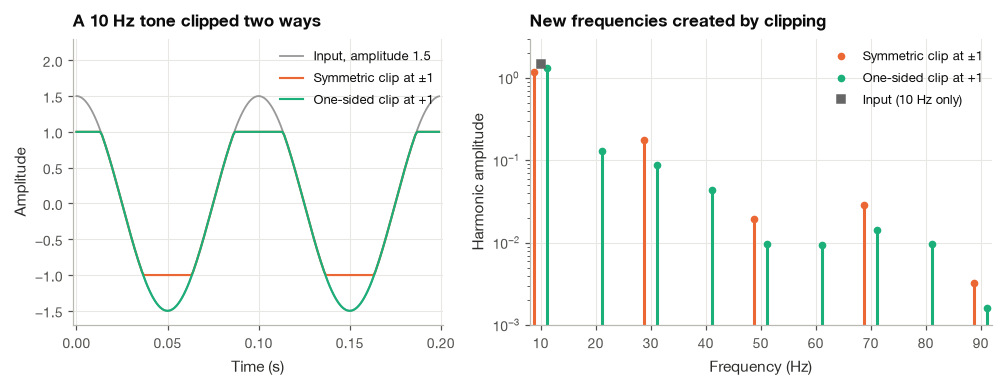

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
show = tt < 0.2
ax.plot(tt[show], x15[show], color="0.6", lw=1.2, label="Input, amplitude 1.5")
for (name, y), c in zip(clipped.items(), (C[1], C[2])):
    ax.plot(tt[show], y[show], color=c, lw=1.4, label=name)
ax.set(xlabel="Time (s)", ylabel="Amplitude", ylim=(-1.7, 2.3), title="A 10 Hz tone clipped two ways")
ax.legend(loc="upper right", fontsize=8.5, ncols=1)

ax = axes[1]
freqs_h = f0 * np.arange(1, n_h + 1)
for (name, amps), c, dx in zip(harm.items(), (C[1], C[2]), (-1.2, 1.2)):
    ax.vlines(freqs_h + dx, 1e-4, np.maximum(amps, 1e-4), color=c, lw=2)
    ax.plot(freqs_h + dx, np.maximum(amps, 1e-4), "o", color=c, ms=4, label=name)
ax.plot(f0, 1.5, "s", color="0.4", ms=5, label="Input (10 Hz only)")
ax.set_yscale("log")
ax.set(xlabel="Frequency (Hz)", ylabel="Harmonic amplitude", ylim=(1e-3, 3), xticks=freqs_h,
       title="New frequencies created by clipping")
ax.legend(loc="upper right", fontsize=8.5)
plt.show()

Symmetric clipping produces energy at 30, 50, 70 and 90 Hz but none at the even harmonics, while one-sided clipping fills in 20, 40, 60 and 80 Hz as well (and a DC shift, not shown). None of these frequencies existed in the input.

(sec-3-2-7)=
## 3.2.7 Clipping a Real ECG, Step by Step

To finish, we watch the same mechanism damage a real ECG. Imagine a wearable recorder whose gain was chosen to make the best use of its converter for a resting ECG, so that the input range corresponds to $\pm 1$ mV at the electrodes. On a still patient this is a sensible design, since the R waves of record 100 are below 1 mV. On a moving patient, baseline wander shifts the whole trace up and down, and the R waves start to hit the rails.

### Step 1: Build the input and pass it through the saturating front end

We add one minute of real baseline wander from `nstdb/bw` to one minute of record 100 and clip the sum at $\pm 1$ mV.

In [16]:
start, dur = 60 * fs, 60 * fs
ecg_long = wfdb.rdrecord("../data/mitdb/100", sampfrom=start, sampto=start + dur).p_signal[:, 0]
bw_long = wfdb.rdrecord("../data/nstdb/bw", sampfrom=start, sampto=start + dur).p_signal[:, 0]
ann = wfdb.rdann("../data/mitdb/100", "atr", sampfrom=start, sampto=start + dur)
r_long = np.array([s - start for s, sym in zip(ann.sample, ann.symbol) if sym in {"N", "A", "V"}])

rail = 1.0                                          # mV, input-referred range of the front end
x_in = ecg_long + bw_long
x_out = np.clip(x_in, -rail, rail)
t_long = np.arange(dur) / fs

clipped_beats = np.mean(np.abs(x_in[r_long]) > rail)
print(f"Samples at the rails: {100 * np.mean(np.abs(x_in) > rail):.1f} %")
print(f"Beats whose R peak is clipped: {100 * clipped_beats:.0f} % of {r_long.size}")

Samples at the rails: 8.4 %
Beats whose R peak is clipped: 43 % of 74


### Step 2: Look at the waveform

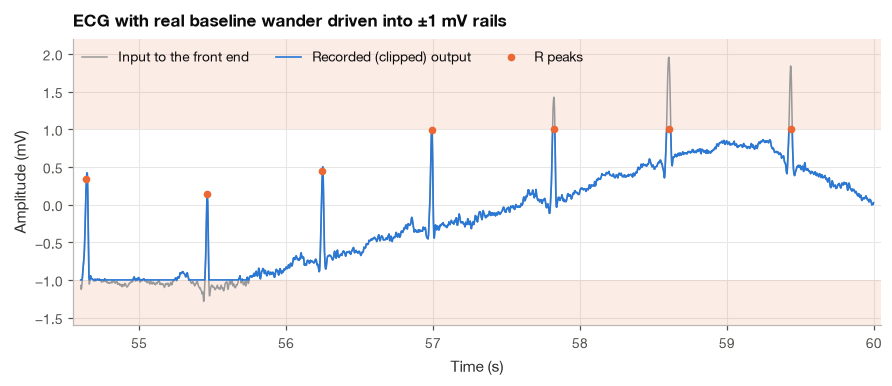

In [17]:
i_worst = r_long[np.argmax(x_in[r_long])]
w0 = max(i_worst - 4 * fs, 0)
w = slice(w0, w0 + 8 * fs)
r_w = r_long[(r_long >= w.start) & (r_long < w.stop)]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(t_long[w], x_in[w], color="0.6", lw=1.0, label="Input to the front end")
ax.plot(t_long[w], x_out[w], color=C[0], lw=1.1, label="Recorded (clipped) output")
ax.axhspan(rail, 2.5, color=C[1], alpha=0.12, lw=0)
ax.axhspan(-2.5, -rail, color=C[1], alpha=0.12, lw=0)
ax.plot(t_long[r_w], x_out[r_w], "o", color=C[1], ms=4, label="R peaks")
ax.set(xlabel="Time (s)", ylabel="Amplitude (mV)", ylim=(-1.6, 2.2),
       title="ECG with real baseline wander driven into ±1 mV rails")
ax.legend(loc="upper left", ncols=3)
plt.show()

Where the baseline drifts upward, the R waves are cut off flat at the upper rail (the shaded band marks the region the front end cannot represent). The heights of those R waves are lost for good: the flat tops carry no information about how tall the peaks really were, so no filter applied afterwards can restore them.

### Step 3: Compare the spectra before and after

We estimate the power spectral density of the input and of the clipped output with Welch's method (the details are the subject of Chapter 7; here we only need to read the plot) and compare the power above 40 Hz, where a clean ECG has very little energy.

In [18]:
f, P_in = signal.welch(x_in, fs, nperseg=4 * fs)
_, P_out = signal.welch(x_out, fs, nperseg=4 * fs)
_, P_ecg = signal.welch(ecg_long, fs, nperseg=4 * fs)
hi = f >= 40
print(f"Power above 40 Hz, input:   {np.sum(P_in[hi]) * (f[1] - f[0]) * 1e3:.3f} x 1e-3 mV²")
print(f"Power above 40 Hz, clipped: {np.sum(P_out[hi]) * (f[1] - f[0]) * 1e3:.3f} x 1e-3 mV²")
print(f"Increase: {10 * np.log10(np.sum(P_out[hi]) / np.sum(P_in[hi])):.1f} dB")

Power above 40 Hz, input:   1.012 x 1e-3 mV²
Power above 40 Hz, clipped: 0.993 x 1e-3 mV²
Increase: -0.1 dB


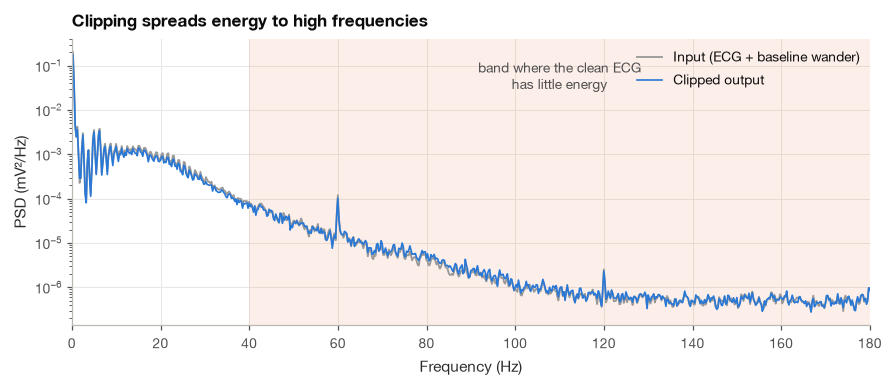

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.semilogy(f, P_in, color="0.6", lw=1.2, label="Input (ECG + baseline wander)")
ax.semilogy(f, P_out, color=C[0], lw=1.1, label="Clipped output")
ax.axvspan(40, fs / 2, color=C[1], alpha=0.1, lw=0)
ax.text(110, 3e-2, "band where the clean ECG\nhas little energy", ha="center", fontsize=9, color="0.3")
ax.set(xlabel="Frequency (Hz)", ylabel="PSD (mV²/Hz)", xlim=(0, fs / 2),
       title="Clipping spreads energy to high frequencies")
ax.legend(loc="upper right")
plt.show()

Below about 20 Hz the two spectra nearly coincide, because most of the signal is unaffected. Above 40 Hz the clipped output carries several times more power than its input. The sharp corners at the edges of each flattened R wave are new, fast features, and fast features require high frequencies to describe them. To a downstream algorithm this extra energy looks like muscle noise, and a QRS detector or a beat classifier that measures R-wave amplitude or high-frequency content will be misled.

```{note}
Saturation must be prevented in hardware, not repaired in software. The usual remedies are a high-pass filter (or a DC-blocking stage) before the high-gain stage, so that offsets and slow wander do not consume the input range, and a converter with enough range and resolution to accept the remaining swings. Quantization and resolution trade-offs are discussed in Section 9.4.
```

## Summary

A system is linear when it satisfies both additivity and homogeneity, or equivalently the superposition principle $\mathcal{T}\{a_1x_1 + a_2x_2\} = a_1\mathcal{T}\{x_1\} + a_2\mathcal{T}\{x_2\}$. Testing a system means computing the response to a combined input from the definition and comparing it with the combination of the individual responses. Worked through in this way, $y = x^2$ fails both conditions because of its squared constants and cross terms; $y = t\,x(t)$ and $y = x(t)\cos(\omega_0 t)$ are linear despite their time-dependent gains; $y = 2x + 3$ is not linear but incrementally linear, a linear system plus a zero-input response; the rectifier fails homogeneity for negative constants; and the median filter is homogeneous but not additive. A linear system maps zero to zero, and a numerical tester with random inputs can disprove linearity but only within the range of inputs it tries.

Superposition is what makes linear systems tractable. It let us judge a baseline remover on a real ECG one component at a time (wander, ECG, muscle noise), while the squarer's cross terms made the same separation impossible. Nonlinear systems also create new frequencies: squaring a tone produces DC and a second harmonic, cubing produces a third harmonic, two tones produce sum and difference frequencies, and clipping an ECG at the rails spreads energy far above the ECG band. In [Section 4.3](index.md) we add time invariance, the second ingredient of LTI systems, together with causality, memory, invertibility and stability, and in [Chapter 4](../ch05_convolution/index.md) the decomposition of signals into impulses turns superposition into the convolution sum.

## Exercises

1. Determine, using the three-step recipe, whether each system is linear: (a) $y(t) = 5\,x(t - 2)$; (b) $y[n] = x[n] + x[n-1]\,x[n+1]$; (c) $y(t) = \int_{-\infty}^{t} x(\tau)\,d\tau$; (d) $y[n] = \operatorname{Re}\{x[n]\}$ for complex inputs. For each nonlinear case give a specific counterexample.
2. Show that every incrementally linear system can be written as $y = \mathcal{L}\{x\} + y_0$, where $\mathcal{L}$ is linear and $y_0 = \mathcal{T}\{0\}$. (Hint: define $\mathcal{L}\{x\} = \mathcal{T}\{x\} - \mathcal{T}\{0\}$ and verify additivity and homogeneity.)
3. Expand $(A_1\cos\omega_1 t + A_2\cos\omega_2 t)^3$ and list every frequency in the result together with its amplitude. Check your list numerically with `harmonic_amplitudes` for $f_1 = 50$ Hz and $f_2 = 60$ Hz.
4. Replace the hard clipper of [Section 3.2.7](#sec-3-2-7) by the soft saturation $y = V\tanh(x/V)$ with $V = 1$ mV. Repeat the spectral comparison on the same ECG with baseline wander. Is the high-frequency increase smaller or larger, and why?
5. Use `test_linearity` on a 200 ms median filter (73 samples at 360 Hz) and on the baseline remover of Section 3.2.5. Then apply both to the noisy ECG of Step 1 and compare how well each one removes the baseline wander. Can superposition be used to evaluate the median filter one component at a time?
6. A colleague claims that an ADC with clipping is "linear except for 2 % of the samples, so linear enough". Using the record of [Section 3.2.7](#sec-3-2-7), measure how the clipping changes (a) the mean R-wave amplitude and (b) the power above 40 Hz as the rail is lowered from 1.4 mV to 0.8 mV in steps of 0.1 mV. Plot both against the percentage of clipped samples and comment on the claim.

## Further Reading

The definitions of linearity and incremental linearity, with many further examples, are in Section 1.6 of {cite:t}`oppenheim1997` and Chapter 1 of {cite:t}`lathi2018`. {cite:t}`semmlow2014` discusses linearity and its limits for biomedical systems, and {cite:t}`rangayyan2015` covers the noise sources used here and the filters that remove them. The noise recordings come from the MIT-BIH Noise Stress Test Database {cite:p}`moody1984`, and the median-filter baseline estimator mentioned in Example 3.2.6 is from {cite:t}`dechazal2004`.